# Multiclass Cyberbullying Detection on Tweets

**Course:** NLP (Natural Language Processing) Mini Project, Experiment 9
**Task:** Multiclass text classification

## Objective
Classify a tweet into the type of cyberbullying it contains, so that harmful content can be flagged automatically and the target group identified.

## Dataset
Cyberbullying Classification (Kaggle, by andrewmvd): about 47,000 tweets labelled with one of 6 classes: age, ethnicity, gender, religion, other cyberbullying, and not cyberbullying.

## Pipeline
1. Data loading and exploration
2. Text cleaning and duplicate removal
3. Stratified train / validation / test split (fixed random seed, shared by the whole team)
4. Feature extraction: TF-IDF (Term Frequency-Inverse Document Frequency)
5. Model training and comparison:
   - Classical models: Logistic Regression, Naive Bayes, SVM (Support Vector Machine), Random Forest, XGBoost, Voting ensemble
   - Deep learning: BiLSTM (Bidirectional Long Short-Term Memory) with attention
   - Transformers: BERT, RoBERTa, DistilBERT, BERTweet
6. Evaluation on the test set using macro-F1 (headline metric), accuracy, precision, recall and a confusion matrix
7. Error analysis and conclusion

## Evaluation metric
Macro-F1 is the main metric. It averages the F1-score of each class, so every class counts equally.

## Rules for fair comparison
- Every model uses the same train / validation / test files.
- The test set is used only once, for the final results.
- Neural models are run with 3 random seeds, and we report the mean and standard deviation.

In [1]:
import sys
import random
import numpy as np

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Python:", sys.version.split()[0])

try:
    import torch
    print("PyTorch:", torch.__version__)
    print("GPU available:", torch.cuda.is_available())
    if torch.cuda.is_available():
        print("GPU name:", torch.cuda.get_device_name(0))
except ImportError:
    print("PyTorch is not installed")

Python: 3.13.16
PyTorch: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4


In [2]:
import glob
import pandas as pd

files = glob.glob("/kaggle/input/**/*.csv", recursive=True)
print("CSV files found:", files)

df = pd.read_csv(files[0])

print("\nShape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nLabel counts (second column):")
print(df.iloc[:, 1].value_counts())

df.head()

CSV files found: ['/kaggle/input/datasets/andrewmvd/cyberbullying-classification/cyberbullying_tweets.csv']

Shape: (47692, 2)
Columns: ['tweet_text', 'cyberbullying_type']

Label counts (second column):
cyberbullying_type
religion               7998
age                    7992
gender                 7973
ethnicity              7961
not_cyberbullying      7945
other_cyberbullying    7823
Name: count, dtype: int64


,tweet_text,cyberbullying_type
0,"In other words #katandandre, your food was cra...",not_cyberbullying
1,Why is #aussietv so white? #MKR #theblock #ImA...,not_cyberbullying
2,@XochitlSuckkks a classy whore? Or more red ve...,not_cyberbullying
3,"@Jason_Gio meh. :P thanks for the heads up, b...",not_cyberbullying
4,@RudhoeEnglish This is an ISIS account pretend...,not_cyberbullying


In [3]:
df = df.rename(columns={"tweet_text": "text", "cyberbullying_type": "label"})

print(df["label"].value_counts())
print("\nMissing values:", df.isna().sum().sum())
print("Exact duplicate texts:", df.duplicated("text").sum())

n_words = df["text"].str.split().str.len()
print("\nWords per tweet:")
print(n_words.describe())
print(n_words.quantile([0.90, 0.95, 0.99]))

for lab, g in df.groupby("label"):
    print(f"\n=== {lab} ===")
    for t in g["text"].sample(3, random_state=1):
        print("-", t[:200])

label
religion               7998
age                    7992
gender                 7973
ethnicity              7961
not_cyberbullying      7945
other_cyberbullying    7823
Name: count, dtype: int64

Missing values: 0
Exact duplicate texts: 1675

Words per tweet:
count    47692.000000
mean        23.704835
std         15.434881
min          1.000000
25%         13.000000
50%         20.000000
75%         32.000000
max        790.000000
Name: text, dtype: float64
0.90    47.0
0.95    51.0
0.99    56.0
Name: text, dtype: float64

=== age ===
- She looks so beautiful and she’s has a very kind heart . The only thing I can say is I was bullied to, but I was a shy over weight little girl. Hold your head up high sweet ness you’re absolutely beau
- My old high school bully just tried to menace and harass me when I was walking in town. Just filed a restraining order on him that sheriffs are serving on him soon
- From my experience PE teachers are bullies. I went on a lovely nature walk the oth

In [4]:
import re
import html

URL = re.compile(r"https?://\S+|www\.\S+")
MENTION = re.compile(r"@\w+")

def clean_text(t):
    t = html.unescape(str(t)).lower()
    t = URL.sub(" ", t)           # remove links
    t = MENTION.sub(" ", t)       # remove @usernames
    t = re.sub(r"^rt\s+", "", t)  # remove retweet marker
    t = t.replace("#", " ")       # keep the hashtag word, drop the symbol
    return re.sub(r"\s+", " ", t).strip()

df["text"] = df["text"].map(clean_text)
df = df[df["text"].str.len() > 0]

print("Rows after cleaning:", len(df))
df.sample(5, random_state=1)

Rows after cleaning: 47473


,text,label
41975,k. michelle ignorant as fuck. only a dumb uned...,ethnicity
3282,by victims you mean daesh terrorists and dicta...,not_cyberbullying
8596,that grizz dude has tweeted rape apologist shi...,gender
23476,if you call yourself a christian yet you suppo...,religion
7632,that's fucking rich from the company draining ...,not_cyberbullying


In [5]:
# Same tweet with different labels is ambiguous, so drop every copy of it.
n_labels = df.groupby("text")["label"].nunique()
conflicting = n_labels[n_labels > 1].index
print("Texts with conflicting labels:", len(conflicting))
df = df[~df["text"].isin(conflicting)]

# Same tweet with the same label: keep one copy.
before = len(df)
df = df.drop_duplicates("text").reset_index(drop=True)
print("Exact duplicates removed:", before - len(df))

print("\nRows left:", len(df))
print(df["label"].value_counts())

Texts with conflicting labels: 1627
Exact duplicates removed: 387

Rows left: 43711
label
religion               7969
age                    7956
ethnicity              7900
gender                 7589
not_cyberbullying      6286
other_cyberbullying    6011
Name: count, dtype: int64


In [6]:
from sklearn.model_selection import train_test_split

train, rest = train_test_split(df, test_size=0.20, stratify=df["label"], random_state=SEED)
val, test = train_test_split(rest, test_size=0.50, stratify=rest["label"], random_state=SEED)

print("train:", len(train), "| val:", len(val), "| test:", len(test))
print("\nClass share per split (%):")
print(pd.concat(
    {n: p["label"].value_counts(normalize=True).mul(100).round(1)
     for n, p in [("train", train), ("val", val), ("test", test)]}, axis=1))

for name, part in [("train", train), ("val", val), ("test", test)]:
    part.to_csv(f"/kaggle/working/{name}.csv", index=False)

train: 34968 | val: 4371 | test: 4372

Class share per split (%):
                     train   val  test
label                                 
religion              18.2  18.2  18.2
age                   18.2  18.2  18.2
ethnicity             18.1  18.1  18.1
gender                17.4  17.4  17.4
not_cyberbullying     14.4  14.4  14.4
other_cyberbullying   13.8  13.7  13.7


In [7]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

results = []

def evaluate(name, group, y_true, y_pred, split="val", seed=SEED):
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    row = {
        "model": name, "group": group, "split": split, "seed": seed,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": p, "macro_recall": r, "macro_f1": f1,
    }
    results.append(row)
    print(f"{name} [{split}] macro-F1={f1:.4f}  accuracy={row['accuracy']:.4f}")
    return row

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train = vec.fit_transform(train["text"])
X_val = vec.transform(val["text"])

lr = LogisticRegression(C=3, max_iter=1000)
lr.fit(X_train, train["label"])

pred = lr.predict(X_val)
evaluate("LogisticRegression (word TF-IDF)", "A-classical", val["label"], pred)
print()
print(classification_report(val["label"], pred, digits=4))

LogisticRegression (word TF-IDF) [val] macro-F1=0.8630  accuracy=0.8776

                     precision    recall  f1-score   support

                age     0.9515    0.9849    0.9679       796
          ethnicity     0.9736    0.9810    0.9773       790
             gender     0.9211    0.8617    0.8904       759
  not_cyberbullying     0.7086    0.6545    0.6805       628
other_cyberbullying     0.6860    0.7271    0.7060       601
           religion     0.9405    0.9724    0.9562       797

           accuracy                         0.8776      4371
          macro avg     0.8636    0.8636    0.8630      4371
       weighted avg     0.8768    0.8776    0.8767      4371



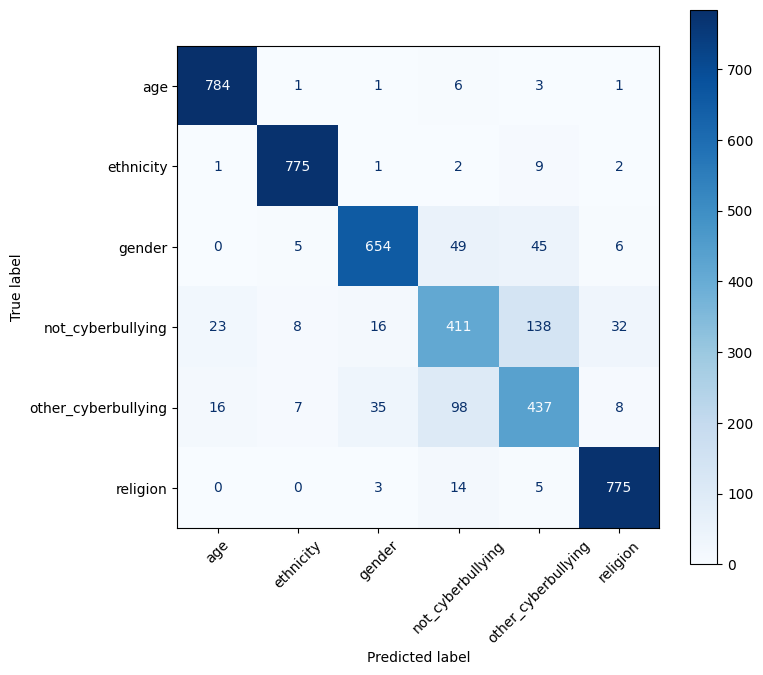

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    val["label"], pred, xticks_rotation=45, cmap="Blues", ax=ax
)
plt.tight_layout()
plt.show()

In [10]:
import time
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

models_A = {"LogisticRegression": lr}
preds_A = {"LogisticRegression": lr.predict(X_val)}

for name, clf in [("NaiveBayes", MultinomialNB(alpha=0.1)),
                  ("LinearSVM", LinearSVC(C=0.5))]:
    t0 = time.time()
    clf.fit(X_train, train["label"])
    p = clf.predict(X_val)
    models_A[name], preds_A[name] = clf, p
    evaluate(f"{name} (word TF-IDF)", "A-classical", val["label"], p)
    print(f"   trained in {time.time() - t0:.1f}s")

NaiveBayes (word TF-IDF) [val] macro-F1=0.7700  accuracy=0.8007
   trained in 0.1s
LinearSVM (word TF-IDF) [val] macro-F1=0.8646  accuracy=0.8794
   trained in 0.7s


In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier

t0 = time.time()
rf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED)
rf.fit(X_train, train["label"])
p = rf.predict(X_val)
models_A["RandomForest"], preds_A["RandomForest"] = rf, p
evaluate("RandomForest (word TF-IDF)", "A-classical", val["label"], p)
print(f"   trained in {time.time() - t0:.1f}s")

le = LabelEncoder().fit(train["label"])
t0 = time.time()
xgb = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                    tree_method="hist", device="cuda",
                    eval_metric="mlogloss", random_state=SEED)
xgb.fit(X_train, le.transform(train["label"]))
p = le.inverse_transform(xgb.predict(X_val))
models_A["XGBoost"], preds_A["XGBoost"] = xgb, p
evaluate("XGBoost (word TF-IDF)", "A-classical", val["label"], p)
print(f"   trained in {time.time() - t0:.1f}s")

RandomForest (word TF-IDF) [val] macro-F1=0.8518  accuracy=0.8659
   trained in 132.5s
XGBoost (word TF-IDF) [val] macro-F1=0.8637  accuracy=0.8769
   trained in 57.0s


/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [17:25:07] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


In [12]:
from scipy.sparse import hstack

char_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3,
                           sublinear_tf=True, max_features=150000)
Xc_train = char_vec.fit_transform(train["text"])
Xc_val = char_vec.transform(val["text"])
XB_train = hstack([X_train, Xc_train]).tocsr()
XB_val = hstack([X_val, Xc_val]).tocsr()
print("Feature matrix (word + char):", XB_train.shape)

models_B = {}
for name, clf in [("LogisticRegression", LogisticRegression(C=3, max_iter=1000)),
                  ("LinearSVM", LinearSVC(C=0.5)),
                  ("NaiveBayes", MultinomialNB(alpha=0.1))]:
    t0 = time.time()
    clf.fit(XB_train, train["label"])
    p = clf.predict(XB_val)
    models_B[name] = clf
    evaluate(f"{name} (word+char TF-IDF)", "B-classical", val["label"], p)
    print(f"   trained in {time.time() - t0:.1f}s")

Feature matrix (word + char): (34968, 177109)
LogisticRegression (word+char TF-IDF) [val] macro-F1=0.8786  accuracy=0.8909
   trained in 52.3s
LinearSVM (word+char TF-IDF) [val] macro-F1=0.8753  accuracy=0.8888
   trained in 3.9s
NaiveBayes (word+char TF-IDF) [val] macro-F1=0.8006  accuracy=0.8229
   trained in 0.2s


In [13]:
from collections import Counter

def hard_vote(pred_dict, priority="LogisticRegression"):
    names = list(pred_dict)
    n = len(pred_dict[priority])
    out = []
    for i in range(n):
        votes = Counter(pred_dict[m][i] for m in names)
        top = max(votes.values())
        winners = [lab for lab, v in votes.items() if v == top]
        first = pred_dict[priority][i]
        out.append(first if first in winners else winners[0])
    return np.array(out)

vote = hard_vote(preds_A)
print("Models voting:", list(preds_A))
evaluate("VotingEnsemble (word TF-IDF)", "A-classical", val["label"], vote)

Models voting: ['LogisticRegression', 'NaiveBayes', 'LinearSVM', 'RandomForest', 'XGBoost']
VotingEnsemble (word TF-IDF) [val] macro-F1=0.8644  accuracy=0.8790


{'model': 'VotingEnsemble (word TF-IDF)',
 'group': 'A-classical',
 'split': 'val',
 'seed': 42,
 'accuracy': 0.8789750629146649,
 'macro_precision': 0.8653227609953057,
 'macro_recall': 0.8652118933753651,
 'macro_f1': 0.864371625832379}

In [14]:
TOKEN = re.compile(r"[a-z0-9']+|[^\sa-z0-9]")

def tokenize(t):
    return TOKEN.findall(t)

MAX_LEN = 60
counter = Counter(tok for t in train["text"] for tok in tokenize(t))
vocab = {"<pad>": 0, "<unk>": 1}
for tok, c in counter.items():
    if c >= 2:
        vocab[tok] = len(vocab)
print("Vocabulary size:", len(vocab))

classes = sorted(train["label"].unique())
label2id = {l: i for i, l in enumerate(classes)}
id2label = {i: l for l, i in label2id.items()}

def encode(texts):
    out = np.zeros((len(texts), MAX_LEN), dtype=np.int64)
    for i, t in enumerate(texts):
        ids = [vocab.get(tok, 1) for tok in tokenize(t)][:MAX_LEN]
        out[i, :len(ids)] = ids
    return out

Xtr_seq = encode(train["text"].tolist())
Xva_seq = encode(val["text"].tolist())
Xte_seq = encode(test["text"].tolist())
ytr = train["label"].map(label2id).values
yva = val["label"].map(label2id).values
yte = test["label"].map(label2id).values
print(Xtr_seq.shape, Xva_seq.shape, Xte_seq.shape)

Vocabulary size: 18011
(34968, 60) (4371, 60) (4372, 60)


In [15]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class BiLSTMAttention(nn.Module):
    def __init__(self, vocab_size, n_classes, emb=200, hidden=128, dropout=0.4):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=0)
        self.lstm = nn.LSTM(emb, hidden, batch_first=True, bidirectional=True)
        self.att = nn.Linear(hidden * 2, 1)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden * 2, n_classes)

    def forward(self, x):
        mask = x != 0
        out, _ = self.lstm(self.drop(self.emb(x)))
        score = self.att(out).squeeze(-1).masked_fill(~mask, -1e9)
        w = torch.softmax(score, dim=1).unsqueeze(-1)
        ctx = (out * w).sum(dim=1)
        return self.fc(self.drop(ctx))

print(BiLSTMAttention(len(vocab), len(classes)))
print("Device:", device)

BiLSTMAttention(
  (emb): Embedding(18011, 200, padding_idx=0)
  (lstm): LSTM(200, 128, batch_first=True, bidirectional=True)
  (att): Linear(in_features=256, out_features=1, bias=True)
  (drop): Dropout(p=0.4, inplace=False)
  (fc): Linear(in_features=256, out_features=6, bias=True)
)
Device: cuda


In [16]:
import copy
from sklearn.metrics import f1_score

def predict_ids(model, X, bs=512):
    model.eval()
    X = torch.tensor(X)
    outs = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            outs.append(model(X[i:i + bs].to(device)).cpu())
    return torch.cat(outs).argmax(1).numpy()

def run_bilstm(seed, epochs=12, patience=3, lr=2e-3, batch=128):
    torch.manual_seed(seed)
    np.random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    model = BiLSTMAttention(len(vocab), len(classes)).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    loader = DataLoader(TensorDataset(torch.tensor(Xtr_seq), torch.tensor(ytr)),
                        batch_size=batch, shuffle=True)

    best_f1, best_state, bad = 0.0, None, 0
    for ep in range(1, epochs + 1):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss_fn(model(xb), yb).backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        f1 = f1_score(yva, predict_ids(model, Xva_seq), average="macro")
        print(f"seed {seed} | epoch {ep:2d} | val macro-F1 {f1:.4f}")
        if f1 > best_f1:
            best_f1, bad, best_state = f1, 0, copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= patience:
                break

    model.load_state_dict(best_state)
    val_pred = [id2label[i] for i in predict_ids(model, Xva_seq)]
    test_pred = [id2label[i] for i in predict_ids(model, Xte_seq)]  # saved, NOT scored yet
    return val_pred, test_pred

In [17]:
SEEDS = [42, 7, 2024]
bilstm_preds = {}

for s in SEEDS:
    vp, tp = run_bilstm(s)
    bilstm_preds[s] = {"val": vp, "test": tp}
    evaluate("BiLSTM + Attention", "C-deep", val["label"], vp, seed=s)

seed 42 | epoch  1 | val macro-F1 0.8409
seed 42 | epoch  2 | val macro-F1 0.8583
seed 42 | epoch  3 | val macro-F1 0.8633
seed 42 | epoch  4 | val macro-F1 0.8700
seed 42 | epoch  5 | val macro-F1 0.8688
seed 42 | epoch  6 | val macro-F1 0.8766
seed 42 | epoch  7 | val macro-F1 0.8750
seed 42 | epoch  8 | val macro-F1 0.8733
seed 42 | epoch  9 | val macro-F1 0.8689
BiLSTM + Attention [val] macro-F1=0.8766  accuracy=0.8886
seed 7 | epoch  1 | val macro-F1 0.8367
seed 7 | epoch  2 | val macro-F1 0.8482
seed 7 | epoch  3 | val macro-F1 0.8652
seed 7 | epoch  4 | val macro-F1 0.8700
seed 7 | epoch  5 | val macro-F1 0.8712
seed 7 | epoch  6 | val macro-F1 0.8700
seed 7 | epoch  7 | val macro-F1 0.8630
seed 7 | epoch  8 | val macro-F1 0.8694
BiLSTM + Attention [val] macro-F1=0.8712  accuracy=0.8838
seed 2024 | epoch  1 | val macro-F1 0.8263
seed 2024 | epoch  2 | val macro-F1 0.8491
seed 2024 | epoch  3 | val macro-F1 0.8636
seed 2024 | epoch  4 | val macro-F1 0.8715
seed 2024 | epoch  5 | 

In [18]:
import gc
import inspect
from torch.utils.data import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding, set_seed)

MAX_TOK = 96

class TweetDataset(Dataset):
    def __init__(self, enc, labels):
        self.enc, self.labels = enc, labels
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = int(self.labels[i])
        return item

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    return {"macro_f1": f1_score(labels, logits.argmax(-1), average="macro")}

def run_transformer(model_name, seed, epochs=3, lr=2e-5, batch=32):
    set_seed(seed)
    tok = AutoTokenizer.from_pretrained(model_name)
    enc = lambda df_: tok(df_["text"].tolist(), truncation=True, max_length=MAX_TOK)
    tr_ds = TweetDataset(enc(train), ytr)
    va_ds = TweetDataset(enc(val), yva)
    te_ds = TweetDataset(enc(test), yte)

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=len(classes), id2label=id2label, label2id=label2id)

    steps = -(-len(tr_ds) // batch) * epochs
    eval_key = ("eval_strategy"
                if "eval_strategy" in inspect.signature(TrainingArguments.__init__).parameters
                else "evaluation_strategy")
    args = TrainingArguments(
        output_dir="/kaggle/working/ckpt", num_train_epochs=epochs, learning_rate=lr,
        per_device_train_batch_size=batch, per_device_eval_batch_size=128,
        weight_decay=0.01, warmup_steps=int(0.1 * steps), fp16=True,
        save_strategy="epoch", load_best_model_at_end=True,
        metric_for_best_model="macro_f1", greater_is_better=True,
        save_total_limit=1, logging_steps=200, report_to="none", seed=seed,
        **{eval_key: "epoch"})
    trainer = Trainer(model=model, args=args, train_dataset=tr_ds, eval_dataset=va_ds,
                      data_collator=DataCollatorWithPadding(tok), compute_metrics=compute_metrics)
    trainer.train()

    val_pred = [id2label[i] for i in trainer.predict(va_ds).predictions.argmax(-1)]
    test_pred = [id2label[i] for i in trainer.predict(te_ds).predictions.argmax(-1)]  # saved, NOT scored yet

    del trainer, model
    gc.collect()
    torch.cuda.empty_cache()
    return val_pred, test_pred

In [19]:
transformer_preds = {}

t0 = time.time()
vp, tp = run_transformer("distilbert-base-uncased", seed=42)
transformer_preds[("DistilBERT", 42)] = {"val": vp, "test": tp}
evaluate("DistilBERT", "D-transformer", val["label"], vp, seed=42)
print(f"Total time: {(time.time() - t0) / 60:.1f} min")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

... (7 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


DistilBERT [val] macro-F1=0.8899  accuracy=0.9014
Total time: 8.4 min


In [20]:
res = pd.DataFrame(results)
res = res[res["split"] == "val"]
table = (res.groupby(["group", "model"])
            .agg(runs=("seed", "count"), macro_f1=("macro_f1", "mean"),
                 std=("macro_f1", "std"), accuracy=("accuracy", "mean"))
            .reset_index()
            .sort_values("macro_f1", ascending=False))
table["std"] = table["std"].fillna(0)
print(table.round(4).to_string(index=False))

        group                                 model  runs  macro_f1    std  accuracy
D-transformer                            DistilBERT     1    0.8899 0.0000    0.9014
  B-classical LogisticRegression (word+char TF-IDF)     1    0.8786 0.0000    0.8909
  B-classical          LinearSVM (word+char TF-IDF)     1    0.8753 0.0000    0.8888
       C-deep                    BiLSTM + Attention     3    0.8743 0.0027    0.8865
  A-classical               LinearSVM (word TF-IDF)     1    0.8646 0.0000    0.8794
  A-classical          VotingEnsemble (word TF-IDF)     1    0.8644 0.0000    0.8790
  A-classical                 XGBoost (word TF-IDF)     1    0.8637 0.0000    0.8769
  A-classical      LogisticRegression (word TF-IDF)     1    0.8630 0.0000    0.8776
  A-classical            RandomForest (word TF-IDF)     1    0.8518 0.0000    0.8659
  B-classical         NaiveBayes (word+char TF-IDF)     1    0.8006 0.0000    0.8229
  A-classical              NaiveBayes (word TF-IDF)     1    0.77

In [21]:
import json

def run_model_seeds(label, model_name, seeds=(42, 7, 2024)):
    for s in seeds:
        key = (label, s)
        if key not in transformer_preds:
            t0 = time.time()
            vp, tp = run_transformer(model_name, seed=s)
            transformer_preds[key] = {"val": vp, "test": tp}
            evaluate(label, "D-transformer", val["label"], vp, seed=s)
            print(f"   {label} seed {s} finished in {(time.time() - t0) / 60:.1f} min")
        with open(f"/kaggle/working/preds_{label}_seed{s}.json", "w") as f:
            json.dump({"model": label, "seed": s, **transformer_preds[key]}, f)

In [22]:
run_model_seeds("DistilBERT", "distilbert-base-uncased")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super(

Epoch,Training Loss,Validation Loss,Macro F1
1,0.888144,0.662850,0.864929
2,0.573357,0.548250,0.890858
3,0.441496,0.543357,0.894426


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (12 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


DistilBERT [val] macro-F1=0.8948  accuracy=0.9055
   DistilBERT seed 2024 finished in 8.3 min


In [23]:
run_model_seeds("BERT-base", "bert-base-uncased")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

... (29 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


BERT-base [val] macro-F1=0.8982  accuracy=0.9092
   BERT-base seed 2024 finished in 16.1 min


In [24]:
run_model_seeds("RoBERTa-base", "roberta-base")

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

... (30 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


RoBERTa-base [val] macro-F1=0.8935  accuracy=0.9048
   RoBERTa-base seed 2024 finished in 16.8 min


In [25]:
run_model_seeds("BERTweet", "vinai/bertweet-base")

config.json:   0%|          | 0.00/558 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/843k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.91M [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  543MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

... (32 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


BERTweet [val] macro-F1=0.8999  accuracy=0.9103
   BERTweet seed 2024 finished in 16.7 min


In [26]:
res = pd.DataFrame(results)
res = res[res["split"] == "val"]
table = (res.groupby(["group", "model"])
            .agg(runs=("seed", "count"), macro_f1=("macro_f1", "mean"),
                 std=("macro_f1", "std"), accuracy=("accuracy", "mean"))
            .reset_index()
            .sort_values("macro_f1", ascending=False))
table["std"] = table["std"].fillna(0)
print(table.round(4).to_string(index=False))

        group                                 model  runs  macro_f1    std  accuracy
D-transformer                              BERTweet     3    0.8987 0.0011    0.9094
D-transformer                             BERT-base     3    0.8969 0.0015    0.9077
D-transformer                          RoBERTa-base     3    0.8939 0.0004    0.9053
D-transformer                            DistilBERT     3    0.8930 0.0028    0.9041
  B-classical LogisticRegression (word+char TF-IDF)     1    0.8786 0.0000    0.8909
  B-classical          LinearSVM (word+char TF-IDF)     1    0.8753 0.0000    0.8888
       C-deep                    BiLSTM + Attention     3    0.8743 0.0027    0.8865
  A-classical               LinearSVM (word TF-IDF)     1    0.8646 0.0000    0.8794
  A-classical          VotingEnsemble (word TF-IDF)     1    0.8644 0.0000    0.8790
  A-classical                 XGBoost (word TF-IDF)     1    0.8637 0.0000    0.8769
  A-classical      LogisticRegression (word TF-IDF)     1    0.86

In [27]:
# Score EVERY model on the test set, once. Selection of the best model still uses validation only.
results[:] = [r for r in results if r["split"] != "test"]   # safe to re-run
test_pred_store = {}

Xte_word = vec.transform(test["text"])
XB_test = hstack([Xte_word, char_vec.transform(test["text"])]).tocsr()

test_preds_A = {}
for name, clf in models_A.items():
    p = le.inverse_transform(clf.predict(Xte_word)) if name == "XGBoost" else clf.predict(Xte_word)
    test_preds_A[name] = p
    test_pred_store[(f"{name} (word TF-IDF)", SEED)] = p
    evaluate(f"{name} (word TF-IDF)", "A-classical", test["label"], p, split="test")

p = hard_vote(test_preds_A)
test_pred_store[("VotingEnsemble (word TF-IDF)", SEED)] = p
evaluate("VotingEnsemble (word TF-IDF)", "A-classical", test["label"], p, split="test")

for name, clf in models_B.items():
    p = clf.predict(XB_test)
    test_pred_store[(f"{name} (word+char TF-IDF)", SEED)] = p
    evaluate(f"{name} (word+char TF-IDF)", "B-classical", test["label"], p, split="test")

for s, d in bilstm_preds.items():
    test_pred_store[("BiLSTM + Attention", s)] = d["test"]
    evaluate("BiLSTM + Attention", "C-deep", test["label"], d["test"], split="test", seed=s)

for (label, s), d in transformer_preds.items():
    test_pred_store[(label, s)] = d["test"]
    evaluate(label, "D-transformer", test["label"], d["test"], split="test", seed=s)

LogisticRegression (word TF-IDF) [test] macro-F1=0.8622  accuracy=0.8756
NaiveBayes (word TF-IDF) [test] macro-F1=0.7665  accuracy=0.7957
LinearSVM (word TF-IDF) [test] macro-F1=0.8652  accuracy=0.8792
RandomForest (word TF-IDF) [test] macro-F1=0.8425  accuracy=0.8566
XGBoost (word TF-IDF) [test] macro-F1=0.8626  accuracy=0.8751
VotingEnsemble (word TF-IDF) [test] macro-F1=0.8664  accuracy=0.8801
LogisticRegression (word+char TF-IDF) [test] macro-F1=0.8756  accuracy=0.8866
LinearSVM (word+char TF-IDF) [test] macro-F1=0.8801  accuracy=0.8916
NaiveBayes (word+char TF-IDF) [test] macro-F1=0.8038  accuracy=0.8237
BiLSTM + Attention [test] macro-F1=0.8714  accuracy=0.8827
BiLSTM + Attention [test] macro-F1=0.8697  accuracy=0.8815
BiLSTM + Attention [test] macro-F1=0.8673  accuracy=0.8797
DistilBERT [test] macro-F1=0.8854  accuracy=0.8964
DistilBERT [test] macro-F1=0.8913  accuracy=0.9016
DistilBERT [test] macro-F1=0.8922  accuracy=0.9026
BERT-base [test] macro-F1=0.8882  accuracy=0.8991
BER

In [28]:
def summarize(split):
    r = pd.DataFrame(results)
    r = r[r["split"] == split]
    return (r.groupby(["group", "model"])
              .agg(runs=("seed", "count"), macro_f1=("macro_f1", "mean"),
                   std=("macro_f1", "std"), accuracy=("accuracy", "mean"),
                   precision=("macro_precision", "mean"), recall=("macro_recall", "mean"))
              .reset_index())

final = summarize("val").merge(summarize("test"), on=["group", "model"], suffixes=("_val", "_test"))
final = final.drop(columns=["runs_test"]).rename(columns={"runs_val": "runs"})
final[["std_val", "std_test"]] = final[["std_val", "std_test"]].fillna(0)
final = final.sort_values("macro_f1_val", ascending=False).reset_index(drop=True)   # ranked by VALIDATION

cols = ["group", "model", "runs", "macro_f1_val", "macro_f1_test", "std_test",
        "accuracy_test", "precision_test", "recall_test"]
print(final[cols].round(4).to_string(index=False))

        group                                 model  runs  macro_f1_val  macro_f1_test  std_test  accuracy_test  precision_test  recall_test
D-transformer                              BERTweet     3        0.8987         0.8917    0.0013         0.9026          0.8926       0.8924
D-transformer                             BERT-base     3        0.8969         0.8869    0.0012         0.8979          0.8882       0.8877
D-transformer                          RoBERTa-base     3        0.8939         0.8919    0.0018         0.9026          0.8930       0.8927
D-transformer                            DistilBERT     3        0.8930         0.8896    0.0037         0.9002          0.8900       0.8902
  B-classical LogisticRegression (word+char TF-IDF)     1        0.8786         0.8756    0.0000         0.8866          0.8761       0.8759
  B-classical          LinearSVM (word+char TF-IDF)     1        0.8753         0.8801    0.0000         0.8916          0.8804       0.8807
       C-deep

Best model (chosen on validation): BERTweet | shown for seed 42

                     precision    recall  f1-score   support

                age     0.9835    0.9761    0.9798       796
          ethnicity     0.9885    0.9823    0.9854       790
             gender     0.9082    0.8999    0.9040       759
  not_cyberbullying     0.7897    0.6804    0.7310       629
other_cyberbullying     0.7340    0.8403    0.7836       601
           religion     0.9509    0.9724    0.9615       797

           accuracy                         0.9021      4372
          macro avg     0.8925    0.8919    0.8909      4372
       weighted avg     0.9032    0.9021    0.9016      4372



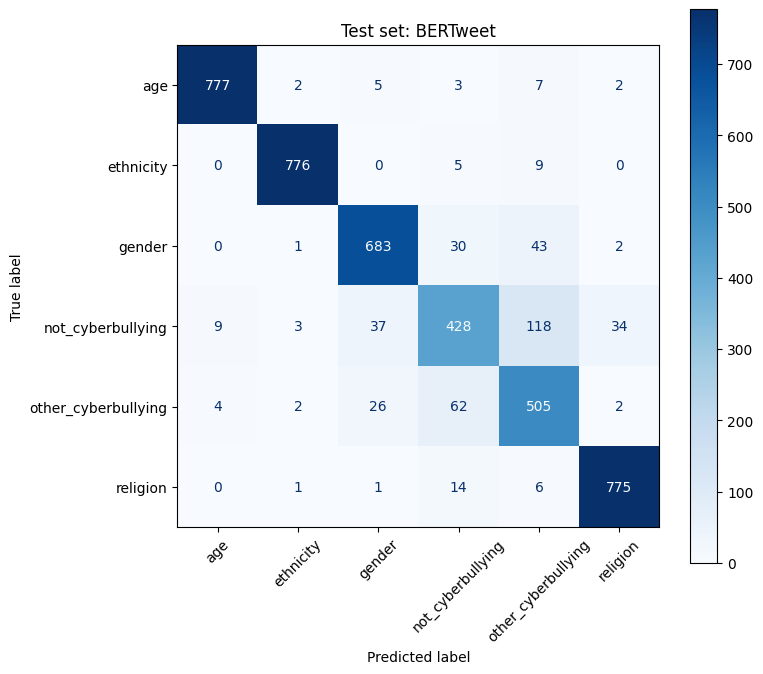

In [29]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

best_name = final.loc[0, "model"]
best_pred = test_pred_store[(best_name, SEED)]
print("Best model (chosen on validation):", best_name, "| shown for seed", SEED)
print()
print(classification_report(test["label"], best_pred, digits=4))

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(test["label"], best_pred, xticks_rotation=45,
                                        cmap="Blues", ax=ax)
plt.title(f"Test set: {best_name}")
plt.tight_layout()
plt.show()

In [30]:
err = test.assign(pred=list(best_pred))
err = err[err["label"] != err["pred"]]
print("Errors:", len(err), "of", len(test))
print("\nMost common mistakes (true -> predicted):")
print(err.groupby(["label", "pred"]).size().sort_values(ascending=False).head(8))

for a, b in [("not_cyberbullying", "other_cyberbullying"),
             ("other_cyberbullying", "not_cyberbullying")]:
    sub = err[(err["label"] == a) & (err["pred"] == b)]
    print(f"\nTrue: {a}  ->  predicted: {b}  ({len(sub)} cases)")
    for t in sub["text"].head(5):
        print("-", t[:220])

Errors: 428 of 4372

Most common mistakes (true -> predicted):
label                pred               
not_cyberbullying    other_cyberbullying    118
other_cyberbullying  not_cyberbullying       62
gender               other_cyberbullying     43
not_cyberbullying    gender                  37
                     religion                34
gender               not_cyberbullying       30
other_cyberbullying  gender                  26
religion             not_cyberbullying       14
dtype: int64

True: not_cyberbullying  ->  predicted: other_cyberbullying  (118 cases)
- you wanna know what's happening? idia is getting bullied by england thirdtest
- that's the batman anthem, if you couldn't figure it out (you probably can't)
- oh, please don't give me a link to harun yahya's silliness. i've already seen it.
- i want her outfit. it's so cute... -eyes sparkle-
- mlp?

True: other_cyberbullying  ->  predicted: not_cyberbullying  (62 cases)
- then why use the word inequality
- thank you for

In [31]:
pd.DataFrame(results).to_csv("/kaggle/working/all_results.csv", index=False)
final.to_csv("/kaggle/working/final_comparison.csv", index=False)
print("Saved: all_results.csv, final_comparison.csv")

Saved: all_results.csv, final_comparison.csv


In [32]:
import shutil
from transformers import pipeline

MODEL_IDS = {"DistilBERT": "distilbert-base-uncased", "BERT-base": "bert-base-uncased",
             "RoBERTa-base": "roberta-base", "BERTweet": "vinai/bertweet-base"}

DEPLOY = "DistilBERT"   # set to None to deploy the best transformer on validation instead
best_tf = DEPLOY or final[final["group"] == "D-transformer"].iloc[0]["model"]
print("Retraining and saving:", best_tf)

def train_and_save(model_name, seed, save_dir, epochs=3, lr=2e-5, batch=32):
    set_seed(seed)
    tok = AutoTokenizer.from_pretrained(model_name)
    enc = lambda df_: tok(df_["text"].tolist(), truncation=True, max_length=MAX_TOK)
    tr_ds, va_ds = TweetDataset(enc(train), ytr), TweetDataset(enc(val), yva)
    model = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=len(classes), id2label=id2label, label2id=label2id)
    steps = -(-len(tr_ds) // batch) * epochs
    eval_key = ("eval_strategy"
                if "eval_strategy" in inspect.signature(TrainingArguments.__init__).parameters
                else "evaluation_strategy")
    args = TrainingArguments(
        output_dir="/kaggle/working/ckpt_final", num_train_epochs=epochs, learning_rate=lr,
        per_device_train_batch_size=batch, per_device_eval_batch_size=128,
        weight_decay=0.01, warmup_steps=int(0.1 * steps), fp16=True,
        save_strategy="epoch", load_best_model_at_end=True,
        metric_for_best_model="macro_f1", greater_is_better=True,
        save_total_limit=1, logging_steps=200, report_to="none", seed=seed,
        **{eval_key: "epoch"})
    trainer = Trainer(model=model, args=args, train_dataset=tr_ds, eval_dataset=va_ds,
                      data_collator=DataCollatorWithPadding(tok), compute_metrics=compute_metrics)
    trainer.train()
    trainer.save_model(save_dir)
    tok.save_pretrained(save_dir)

shutil.rmtree("/kaggle/working/ckpt", ignore_errors=True)
train_and_save(MODEL_IDS[best_tf], SEED, "/kaggle/working/best_model")
shutil.rmtree("/kaggle/working/ckpt_final", ignore_errors=True)

# quick check: reload from disk and predict
clf_pipe = pipeline("text-classification", model="/kaggle/working/best_model",
                    top_k=None, device=0)
for text, out in zip(test["text"].head(3), clf_pipe(test["text"].head(3).tolist())):
    print("\n", text[:120])
    print(sorted(out, key=lambda d: -d["score"])[:3])

shutil.make_archive("/kaggle/working/best_model", "zip", "/kaggle/working/best_model")
print("\nZipped: /kaggle/working/best_model.zip")

Retraining and saving: DistilBERT


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super(

Epoch,Training Loss,Validation Loss,Macro F1
1,0.865314,0.657554,0.861536
2,0.552532,0.561182,0.886648
3,0.433072,0.551151,0.889872


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


 i know this is petty but i love seeing the girls who bullied me in high school get fat. that shit genuinely puts me in a
[{'label': 'age', 'score': 0.997080385684967}, {'label': 'not_cyberbullying', 'score': 0.0008450949098914862}, {'label': 'other_cyberbullying', 'score': 0.0006117499433457851}]

 oki i'll be one of ur first customers!
[{'label': 'ethnicity', 'score': 0.9878985285758972}, {'label': 'not_cyberbullying', 'score': 0.005345504265278578}, {'label': 'other_cyberbullying', 'score': 0.0031369710341095924}]

 lil white girl prolly was bullied in high school poor girl.
[{'label': 'age', 'score': 0.996886670589447}, {'label': 'not_cyberbullying', 'score': 0.0008572850492782891}, {'label': 'gender', 'score': 0.0006361952400766313}]

Zipped: /kaggle/working/best_model.zip


In [33]:
import os
import glob
import zipfile
from IPython.display import FileLink, display

os.chdir("/kaggle/working")

files = glob.glob("/kaggle/working/*.csv") + glob.glob("/kaggle/working/*.json")
with zipfile.ZipFile("results_bundle.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in files:
        z.write(f, arcname=os.path.basename(f))
        print("added:", os.path.basename(f), f"({os.path.getsize(f) / 1e6:.2f} MB)")

print(f"\nresults_bundle.zip: {os.path.getsize('results_bundle.zip') / 1e6:.2f} MB")
display(FileLink("results_bundle.zip"))

added: test.csv (0.63 MB)
added: all_results.csv (0.01 MB)
added: final_comparison.csv (0.00 MB)
added: val.csv (0.63 MB)
added: train.csv (5.07 MB)
added: preds_BERTweet_seed2024.json (0.12 MB)
added: preds_DistilBERT_seed42.json (0.12 MB)
added: preds_BERTweet_seed7.json (0.12 MB)
added: preds_BERTweet_seed42.json (0.12 MB)
added: preds_BERT-base_seed2024.json (0.12 MB)
added: preds_BERT-base_seed7.json (0.12 MB)
added: preds_DistilBERT_seed7.json (0.12 MB)
added: preds_RoBERTa-base_seed7.json (0.12 MB)
added: preds_DistilBERT_seed2024.json (0.12 MB)
added: preds_BERT-base_seed42.json (0.12 MB)
added: preds_RoBERTa-base_seed42.json (0.12 MB)
added: preds_RoBERTa-base_seed2024.json (0.12 MB)

results_bundle.zip: 2.54 MB


/kaggle/working/results_bundle.zip

In [34]:
if os.path.exists("best_model.zip"):
    print(f"best_model.zip: {os.path.getsize('best_model.zip') / 1e6:.0f} MB")
    display(FileLink("best_model.zip"))
else:
    print("best_model.zip not found. Run Cell 32 first.")

best_model.zip: 247 MB


/kaggle/working/best_model.zip